# Check BRS Mseed Data Manually

Manual quality check of downloaded MiniSEED waveforms before running the automated BRS pipeline. This notebook:

- Loads LIGO Hanford **LIV** translation (IX) and rotation (tilt) channels from a chosen download folder and time window
- Applies downsampling, instrument correction (velocity for translation, sensitivity for rotation), and rotation to **NEZ** using station metadata
- Handles tilt-specific conventions (dummy JZ trace, E/N swap) so rotation components align with the translation sensor frame
- Detrends, tapers, bandpass-filters, and rotates both streams to **radial/transverse** using the event backazimuth
- Plots overlay comparisons (e.g. vertical velocity vs. transverse rotation) to visually verify amplitudes, timing, and coherency
- Optionally differentiates traces to compare **rotation rate** with **translational acceleration** on the same axes

Configure `path_to_data`, `tbeg`/`tend`, and `ev_back` at the top (or use the commented alternative event block).

In [1]:
import os
import numpy as np
import obspy as obs

from obspy.signal.rotate import rotate2zne
from matplotlib import pyplot as plt


### Configurations

In [2]:
# specify path to downloaded data
path_to_data = "./data/downloads/Jun28.2024/"

# specify the time range of the data to load
tbeg = obs.UTCDateTime("2024-06-28T05:40:00")
tend = obs.UTCDateTime("2024-06-28T06:30:00")

# specify the sampling rate code of the station
code = "D"

# specify the event backazimuth
ev_back = 158.9 # JUN28

Alternative event (uncomment to run)

In [3]:
# # specify path to downloaded data
# path_to_data = "./data/downloads/Dec08.2025/"

# # specify the time range of the data to load
# tbeg = obs.UTCDateTime("2025-12-08T14:15:00")
# tend = obs.UTCDateTime("2025-12-08T15:40:00")

# # specify the sampling rate code of the station
# code = "D"

# # specify the event backazimuth
# ev_back = 322.9 # DEC08


## Load Translation Data

Get station metadata

In [4]:
inv_tra = obs.read_inventory("./metadata/LIGO_HAN_LIV_AB.xml")

In [5]:
st_tra = obs.Stream()

tra_seeds = [f"LI_LIV_IX_{code}HZ", f"LI_LIV_IX_{code}HY", f"LI_LIV_IX_{code}HX"]

for seed in tra_seeds:
    st_tra += obs.read(path_to_data+seed+".ms")


### Apply Processing

3 Trace(s) in Stream:
LI.LIV.IX.BHX | 2024-06-28T05:40:00.000000Z - 2024-06-28T06:30:00.000000Z | 20.0 Hz, 60001 samples
LI.LIV.IX.BHY | 2024-06-28T05:40:00.000000Z - 2024-06-28T06:30:00.000000Z | 20.0 Hz, 60001 samples
LI.LIV.IX.BHZ | 2024-06-28T05:40:00.000000Z - 2024-06-28T06:30:00.000000Z | 20.0 Hz, 60001 samples


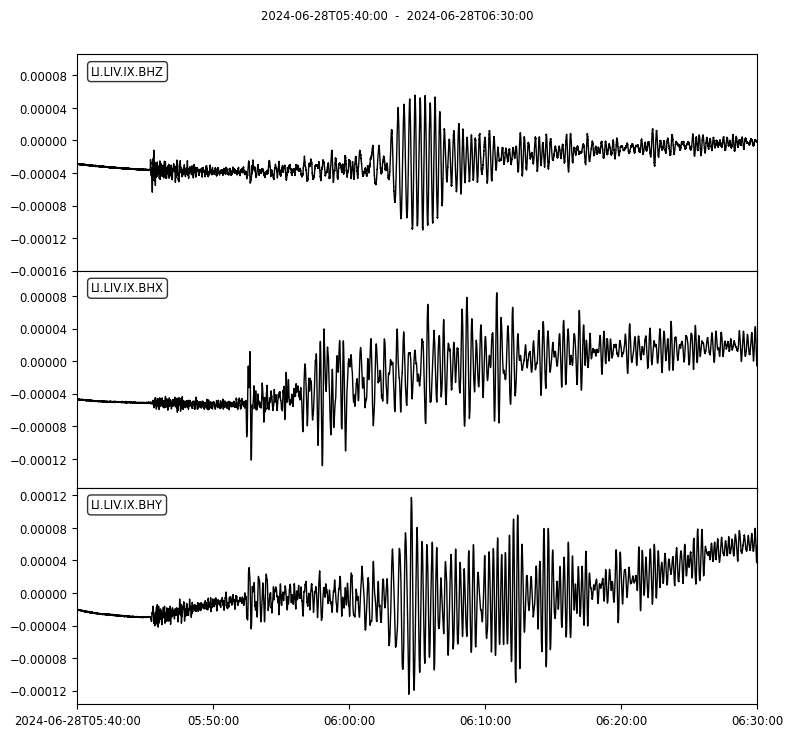

In [6]:

# anti aliasing and downsampling
st_tra = st_tra.filter("lowpass", freq=50, corners=4, zerophase=True)
st_tra = st_tra.resample(100, no_filter=True)
st_tra = st_tra.filter("lowpass", freq=10, corners=4, zerophase=True)
st_tra = st_tra.resample(20, no_filter=True)

# rename channels
for tr in st_tra:
    tr.stats.channel = "B"+tr.stats.channel[1:]

# remove the response
st_tra = st_tra.remove_response(inventory=inv_tra, output="VEL", plot=False, water_level=61)

# trim the data to the time range
st_tra = st_tra.trim(tbeg, tend)

# sort the data
st_tra = st_tra.sort()

print(st_tra)

st_tra.plot();

Rotate the data to NEZ

In [140]:
# # st_tra = st_tra.rotate(method="->ZNE", inventory=inv_tra)
# st_tra._rotate_to_zne(inv_tra, components=('ZXY'))

# get the orientation of the data
angles_tra = {}
for _seed in tra_seeds:
    _seed = _seed.replace("DH", "BH").replace("_", ".")
    angles_tra[_seed] = inv_tra.get_orientation(_seed, tbeg)

Z, N, E = rotated_data = rotate2zne(
    st_tra.select(station="LIV", channel="*HZ")[0].data, angles_tra["LI.LIV.IX.BHZ"]['azimuth'], angles_tra["LI.LIV.IX.BHZ"]['dip'],
    st_tra.select(station="LIV", channel="*HY")[0].data, angles_tra["LI.LIV.IX.BHY"]['azimuth'], angles_tra["LI.LIV.IX.BHY"]['dip'],
    st_tra.select(station="LIV", channel="*HX")[0].data, angles_tra["LI.LIV.IX.BHX"]['azimuth'], angles_tra["LI.LIV.IX.BHX"]['dip'],
)

# ZYX > ZNE
st_tra.select(station="LIV", channel="*HY")[0].data = N
st_tra.select(station="LIV", channel="*HY")[0].stats.channel = code+"HN"
st_tra.select(station="LIV", channel="*HX")[0].data = E
st_tra.select(station="LIV", channel="*HX")[0].stats.channel = code+"HE"

st_tra.plot(equal_scale=False);

can't invoke "event" command: application has been destroyed
    while executing
"event generate $w <<ThemeChanged>>"
    (procedure "ttk::ThemeChanged" line 6)
    invoked from within
"ttk::ThemeChanged"


## Load Rotation Data

In [141]:
st_rot = obs.Stream()

rot_seeds = ["LI_LIV_IX_DJY", "LI_LIV_IY_DJX"]

for seed in rot_seeds:
    st_rot += obs.read(path_to_data+seed+".ms")


Get station metadata

In [142]:
inv_rot = obs.read_inventory("./metadata/LIGO_HAN_LIV_AB.xml")

### Apply Processing

In [143]:
# anti aliasing and downsampling
st_rot = st_rot.filter("lowpass", freq=50, corners=4, zerophase=True)
st_rot = st_rot.resample(100, no_filter=True)
st_rot = st_rot.filter("lowpass", freq=10, corners=4, zerophase=True)
st_rot = st_rot.resample(20, no_filter=True)

# rename channels
for tr in st_rot:
    tr.stats.channel = "B"+tr.stats.channel[1:]

# remove the response (here only the gain)
st_rot = st_rot.remove_sensitivity(inventory=inv_rot);

# trim the data to the time range
st_rot.trim(tbeg, tend)

print(st_rot)

st_rot.plot(equal_scale=False);

2 Trace(s) in Stream:
LI.LIV.IX.BJY | 2024-06-28T05:40:00.000000Z - 2024-06-28T06:30:00.000000Z | 20.0 Hz, 60001 samples
LI.LIV.IY.BJX | 2024-06-28T05:40:00.000000Z - 2024-06-28T06:30:00.000000Z | 20.0 Hz, 60001 samples


In [144]:
# add dummy trace for JZ
dummy_trace = st_rot[0].copy()
dummy_trace.data = np.zeros(len(dummy_trace.data))
dummy_trace.stats.channel = code+"JZ"
st_rot += dummy_trace

st_rot = st_rot.sort()

In [145]:
# correct amplitudes from paul which has it in nanorad and nanometer/s

# for tr in st_rot:
#     tr.data = tr.data / 1e9

In [146]:
# st_rot = st_rot.rotate(method="->ZNE", inventory=inv_rot)
# st_rot._rotate_to_zne(inv_rot, components=('ZXY'))

angles_rot = {}
for _seed in rot_seeds:
    _seed = _seed.replace("DJ", "BJ").replace("_", ".")
    angles_rot[_seed] = inv_rot.get_orientation(_seed, tbeg)

Z, N, E = rotated_data = rotate2zne(
    st_rot.select(station="LIV", channel="*JZ")[0].data, 0, 90,
    st_rot.select(station="LIV", channel="*JY")[0].data, angles_rot["LI.LIV.IX.BJY"]['azimuth'], angles_rot["LI.LIV.IX.BJY"]['dip'],
    st_rot.select(station="LIV", channel="*JX")[0].data, angles_rot["LI.LIV.IY.BJX"]['azimuth'], angles_rot["LI.LIV.IY.BJX"]['dip'],
)

# ZYX > ZNE
st_rot.select(station="LIV", channel="*JY")[0].data = N
st_rot.select(station="LIV", channel="*JY")[0].stats.channel = code+"JN"
st_rot.select(station="LIV", channel="*JX")[0].data = E
st_rot.select(station="LIV", channel="*JX")[0].stats.channel = code+"JE"

st_rot.plot(equal_scale=False);

For tilt the definition of rotation has to be changed

In [147]:
# for tiltmeter defintion E and N have to be swapped
north_tilt = st_rot.select(station="LIV", channel="*JE")[0].data
east_tilt = st_rot.select(station="LIV", channel="*JN")[0].data

st_rot.select(station="LIV", channel="*JE")[0].data = east_tilt
st_rot.select(station="LIV", channel="*JN")[0].data = north_tilt


## Processing 

In [148]:
# apply detrend, taper and bandpass filter
st_tra = st_tra.detrend("linear")
st_tra = st_tra.detrend("demean")
st_tra = st_tra.taper(max_percentage=0.05)
st_tra =st_tra.filter("bandpass", freqmin=0.01, freqmax=0.1, zerophase=True, corners=4)

st_rot = st_rot.detrend("linear")
st_rot = st_rot.detrend("demean")
st_rot = st_rot.taper(max_percentage=0.05)
st_rot = st_rot.filter("bandpass", freqmin=0.01, freqmax=0.1, zerophase=True, corners=4)


Rotate to radial and transverse components

In [149]:
st_tra_zrt = st_tra.copy()

R, T = obs.signal.rotate.rotate_ne_rt(
    st_tra_zrt.select(component="N")[0].data,
    st_tra_zrt.select(component="E")[0].data,
    ev_back
)

st_tra_zrt.select(component="N")[0].data = R
st_tra_zrt.select(component="E")[0].data = T

st_tra_zrt.select(component="N")[0].stats.channel = "LHR"
st_tra_zrt.select(component="E")[0].stats.channel = "LHT"

st_tra_zrt.plot(equal_scale=False);


st_rot_zrt = st_rot.copy()

R, T = obs.signal.rotate.rotate_ne_rt(
    st_rot_zrt.select(component="N")[0].data,
    st_rot_zrt.select(component="E")[0].data,
    ev_back
)

st_rot_zrt.select(component="N")[0].data = R
st_rot_zrt.select(component="E")[0].data = T

st_rot_zrt.select(component="N")[0].stats.channel = "LJR"
st_rot_zrt.select(component="E")[0].stats.channel = "LJT"

st_rot_zrt.plot(equal_scale=False);


## Plotting

In [150]:
%matplotlib tk

### Make an overlay plot

In [ ]:

fig, ax = plt.subplots(1, 1, figsize=(15, 8))

tscale = 1/60
y1scale = 1e9
y2scale = 1e6

ax.plot(
    st_tra_zrt.select(component="Z")[0].times(reftime=tbeg)*tscale,
    st_tra_zrt.select(component="Z")[0].data*y2scale,
    label="HZ", color="black"
)

max_abs = np.max(np.abs(st_tra_zrt.select(component="Z")[0].data*y2scale))
ax.set_ylim(-max_abs, max_abs)
ax_twist = ax.twinx()

ax_twist.plot(
    st_rot_zrt.select(component="T")[0].times(reftime=tbeg)*tscale,
    st_rot_zrt.select(component="T")[0].data*y1scale,
    label="JT", color="red"
)

max_abs = np.max(np.abs(st_rot_zrt.select(component="T")[0].data*y1scale))
ax_twist.set_ylim(-max_abs, max_abs)

ax.set_ylabel("Vertical Velocity [$\mu$m/s]", fontsize=14)
ax_twist.set_ylabel("Rotation [nrad]", fontsize=14)

ax.set_xlabel("Time [min]", fontsize=14)

ax.tick_params(axis='both', labelsize=14)
ax_twist.tick_params(axis='both', labelsize=14)

ax.legend();
plt.show()


## Get Rotation Rate and Acceleration for Comparison

Differentiate once to get to rotational velocity/rate and translational acceleration

In [152]:
# adjust to get rotation rate and acceleration
east_rotation_rate = st_rot.select(station="LIV", channel="*JE").differentiate()[0].data
north_rotation_rate = st_rot.select(station="LIV", channel="*JN").differentiate()[0].data
st_rot.select(station="LIV", channel="*JE")[0].data = east_rotation_rate
st_rot.select(station="LIV", channel="*JN")[0].data = north_rotation_rate

vertical_velocity = st_tra.select(station="LIV", channel="*HZ").differentiate()[0].data
north_acceleration = st_tra.select(station="LIV", channel="*HN").differentiate()[0].data
east_acceleration = st_tra.select(station="LIV", channel="*HE").differentiate()[0].data
st_tra.select(station="LIV", channel="*HN")[0].data = north_acceleration
st_tra.select(station="LIV", channel="*HE")[0].data = east_acceleration
st_tra.select(station="LIV", channel="*HZ")[0].data = vertical_velocity

In [153]:
st_tra_zrt = st_tra.copy()

R, T = obs.signal.rotate.rotate_ne_rt(
    st_tra_zrt.select(component="N")[0].data,
    st_tra_zrt.select(component="E")[0].data,
    ev_back
)

st_tra_zrt.select(component="N")[0].data = R
st_tra_zrt.select(component="E")[0].data = T

st_tra_zrt.select(component="N")[0].stats.channel = "LHR"
st_tra_zrt.select(component="E")[0].stats.channel = "LHT"


st_rot_zrt = st_rot.copy()

R, T = obs.signal.rotate.rotate_ne_rt(
    st_rot_zrt.select(component="N")[0].data,
    st_rot_zrt.select(component="E")[0].data,
    ev_back
)

st_rot_zrt.select(component="N")[0].data = R
st_rot_zrt.select(component="E")[0].data = T

st_rot_zrt.select(component="N")[0].stats.channel = "LJR"
st_rot_zrt.select(component="E")[0].stats.channel = "LJT"



In [154]:
fig, ax = plt.subplots(1, 1, figsize=(15, 8))

tscale = 1/60
y1scale = 1e9
y2scale = 1e6

ax.plot(
    st_tra_zrt.select(component="Z")[0].times(reftime=tbeg)*tscale,
    st_tra_zrt.select(component="Z")[0].data*y2scale,
    label="HZ", color="black"
)

max_abs = np.max(np.abs(st_tra_zrt.select(component="Z")[0].data*y2scale))
ax.set_ylim(-max_abs, max_abs)
ax_twist = ax.twinx()

ax_twist.plot(
    st_rot_zrt.select(component="T")[0].times(reftime=tbeg)*tscale,
    st_rot_zrt.select(component="T")[0].data*y1scale,
    label="JT", color="red"
)

max_abs = np.max(np.abs(st_rot_zrt.select(component="T")[0].data*y1scale))
ax_twist.set_ylim(-max_abs, max_abs)

ax.set_ylabel("Vertical Velocity [$\mu$m/s$^2$]", fontsize=14)
ax_twist.set_ylabel("Rotation [nrad/s]", fontsize=14)

ax.set_xlabel("Time [min]", fontsize=14)

ax.tick_params(axis='both', labelsize=14)
ax_twist.tick_params(axis='both', labelsize=14)

ax.legend();
plt.show()